# 學生學習與作業版｜任務 4：描述統計與視覺化
**姓名：**曾安頡　**學號／組別：**C114118126　**完成日期：**11/12

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [ ]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Google Gemini；我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：
  1. 平均數會把所有數值加總平均，因此非常容易被極端值拉高或拉低；中位數只看排序後的中間位置，對極端值較不敏感（抗極端值能力較強）。
  2. 兩者各有使用限制：平均數在有極端值時會失真，而中位數則會忽略極端數值的實際大小且無法用來推算總和，因此分析時不能只看單一統計量，需一起搭配 `describe()` 觀察分布。
- 我的理解與具體例子：以 `[2, 3, 4, 5, 6]` 為例，加入極端值前，平均數與中位數都是 `4.0`；但若加入一個極端值 `22` 變成 `[2, 3, 4, 5, 6, 22]`，平均數會直接被拉高到 `7.0`（暴增 3.0，甚至比原本大多數數值都高），而中位數只微幅上升到 `4.5`（只增加 0.5）。我在 Python 環境實際用 `pd.Series` 執行 `.mean()` 與 `.median()`，驗證結果與手算完全一致。
- 查證來源／方式及日期（無法查證請註明）：
  1. 課程教材《4.1 敘述統計》（核對 `describe()` 欄位定義及極端值影響平均之觀念，查證日期：2026-11-13）。
  2. 於 Python 環境實際執行 `pd.Series([2, 3, 4, 5, 6])` 與加入 `22` 後的 `.mean()`、`.median()` 程式驗證數值變化（查證日期：2026-11-13）。
- 我檢查或修正 AI 回答的地方：確認 AI 提供的手算過程與 Python 驗證程式皆無誤，並呼應教材 4.1 提醒的「不能只看單一統計量」，將重點精簡整理填入作答區。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


<Figure size 700x400 with 0 Axes>

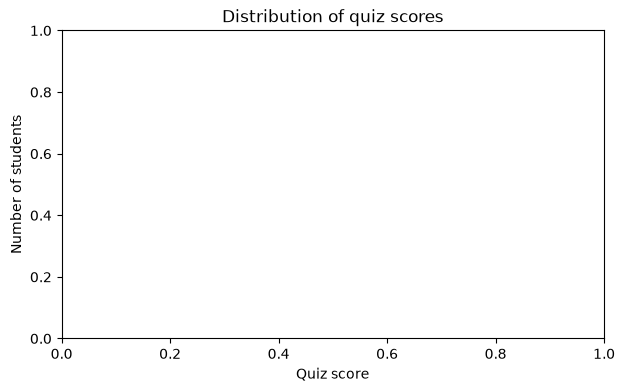

有效成績筆數： 60


In [2]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
plt.figure(figsize=(7, 4)) # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [3]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


### ✍️ 作業 04-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：Google Gemini；我將任務 04-P1 的說明與程式碼截圖提供給 AI，請 AI 協助補齊 `____` 繪製排除缺失值、分成 10 箱的 `quiz_score` 直方圖，並保留既有標題與座標軸[cite: 8, 9]。
- 我補上的程式在做什麼：我在 `____` 的位置補上了 `plt.hist(df["quiz_score"].dropna(), bins=10)`[cite: 8]。這段語法先取出 `quiz_score` 欄位並用 `.dropna()` 排除缺失值，再呼叫 `plt.hist(..., bins=10)` 繪製分成 10 個區間（分箱）的直方圖，同時不修改原始資料表 `df`[cite: 8]。
- 執行或驗證遇到的問題與修正：先確認已執行本單元「共用資料準備」建立 `df` 與匯入 `matplotlib.pyplot as plt` 後，依序執行補齊的繪圖格與自動驗證格，過程順利、無任何報錯[cite: 8, 9]。
- 檢查結果及我如何確認：執行自動驗證格順利通過 `assert df["quiz_score"].notna().sum() == 60` 並印出提示訊息[cite: 9]；同時我也人工檢查了上方繪製出的直方圖，確認標題（`Distribution of quiz scores`）、X/Y 軸標籤（`Quiz score`、`Number of students`）與 10 個分箱顯示皆正確，下方也輸出有效成績筆數為 `60`[cite: 8, 9]。


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Google Gemini；我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：
  1. 調整直方圖的 `bins` 只是改變數值區間的切分寬度，外觀會隨分箱粗細改變，但原始資料的數值、筆數與統計量完全不會改變[cite: 8]。
  2. 直方圖適合觀察「整體分布形狀與各區間人數密度」[cite: 8]；盒鬚圖則適合觀察「中位數、中間 50% 資料的集中範圍（四分位距）以及離群點位置」。
  3. 離群點在統計上只代表數值遠離多數族群，不一定是輸入錯誤（例如每日螢幕時間 15 小時雖屬極端但仍合理，只有像超過 24 小時才確定是資料錯誤），處理前須先依實際情境判斷。
- 我的理解與具體例子：直方圖改變 `bins` 就像用不同倍率的放大鏡看同一批分數，切得越細（`bins` 越大）長條越細碎、切得越寬（`bins` 越小）長條越平滑，但學生的實際分數完全沒變[cite: 8]。我在 Python 環境用 12 筆含極端值 `15.0` 的模擬資料，分別畫出 `bins=4`、`bins=10` 的直方圖與盒鬚圖，驗證兩種分箱圖形外觀不同但資料筆數（12 筆）與中位數（4.05）完全一致，且盒鬚圖能清楚標出 `15.0` 這個離群點。
- 查證來源／方式及日期（無法查證請註明）：
  1. 課程教材《4.2 直方圖》（核對調整 `bins` 只改變切分方式、不改變資料本身之觀念，查證日期：2026-11-13）[cite: 8]。
  2. 於 Python 環境實際執行 `plt.hist(..., bins=4)`、`bins=10` 與 `plt.boxplot(...)` 驗證圖形變化與統計量一致性（查證日期：2026-11-13）。
- 我檢查或修正 AI 回答的地方：確認 AI 完整回答了「`bins` 改變為何外觀改變且資料不變」的任務問題[cite: 10]，並核對課程教材 4.2 的觀念說明後[cite: 8]，精簡整理填入作答區。


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


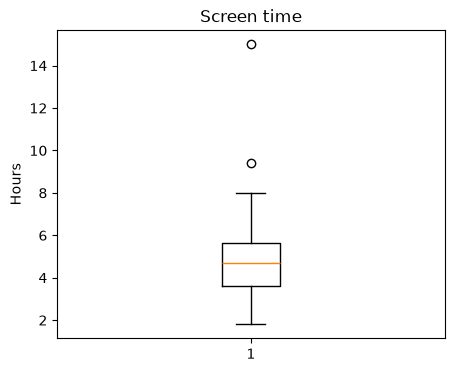

大於 10 小時： 1


In [4]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [5]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


分箱數 5 各箱人數 [ 5  9 20 18  8] 加總 60
分箱數 10 各箱人數 [ 3  2  3  6  9 11 13  5  5  3] 加總 60


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


In [ ]:
# 學生小任務 MA：請在此撰寫你的程式
# 執行前先確認上方資料準備與必要 cell 已執行；可新增其他程式 cell。
# TODO：依任務要求加入程式；完成後執行並保留輸出。

# 步驟 1：檢查資料形狀（幾列、幾欄），僅讀取屬性，不會修改原始 df
print("1. 資料形狀 (列數, 欄數)：", df.shape)

# 步驟 2：計算並列出各欄位的缺失值（NaN）數量
print("\n2. 各欄位缺失值數量：")
print(df.isna().sum())

# 步驟 3：使用布林條件篩選 screen_time_hours 超過 10 小時的紀錄並計算筆數（不更動 df）
over_10_mask = df["screen_time_hours"] > 10
over_10_count = over_10_mask.sum()
print("\n3. 每日螢幕時間超過 10 小時的筆數：", over_10_count)

# 步驟 4：繪製 quiz_score 直方圖（排除缺失值、分成 10 箱，使用英文標籤避免字型問題）
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black")
plt.title("Distribution of quiz_score")
plt.xlabel("Quiz Score")
plt.ylabel("Number of Students")
plt.show()

資料形狀： (60, 7)

各欄缺失數：
 student_id           0
department           0
sleep_hours          2
screen_time_hours    0
study_hours          0
attendance_rate      0
quiz_score           0
dtype: int64

螢幕時間超過 10 小時的筆數： 1


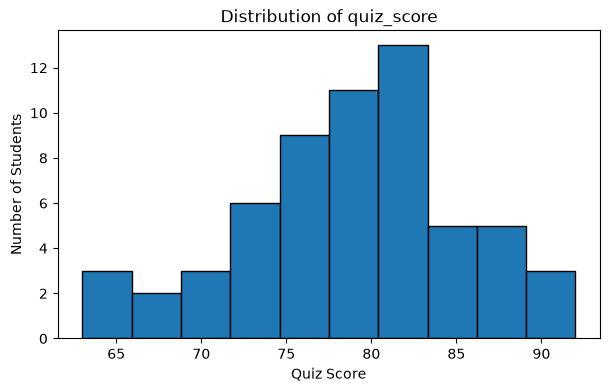

In [7]:
# 1. 資料形狀 (列數, 欄數)
print("資料形狀：", df.shape)

# 2. 各欄缺失數
print("\n各欄缺失數：\n", df.isna().sum())

# 3. 超過 10 小時的筆數（針對每日螢幕時間 screen_time_hours）
print("\n螢幕時間超過 10 小時的筆數：", (df["screen_time_hours"] > 10).sum())

# 4. 繪製 quiz_score 直方圖（排除缺失值、分成 10 箱）
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black")
plt.title("Distribution of quiz_score")
plt.xlabel("Quiz Score")
plt.ylabel("Number of Students")
plt.show()

### 執行驗證

In [6]:
# 驗證 1：確認原始資料表 df 依然完整保留（未被刪除或覆寫）
assert df.shape[0] == 60, "錯誤：原始資料筆數遭到更動"
print(f"驗證一通過：原始 df 完整保留 {df.shape[0]} 列、{df.shape[1]} 欄。")

# 驗證 2：人工列印出 screen_time_hours > 10 的實際資料列，核對筆數與數值是否一致
print("驗證二：螢幕時間超過 10 小時的實際紀錄如下：")
display(df[df["screen_time_hours"] > 10][["student_id", "screen_time_hours"]])

驗證一通過：原始 df 完整保留 60 列、7 欄。
驗證二：螢幕時間超過 10 小時的實際紀錄如下：


,student_id,screen_time_hours
8,9,15.0


### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：針對學生學習與作息模擬資料表 `df` 進行資料健檢與成績分布視覺化，主要檢視全表維度與缺失狀況，並重點分析 `screen_time_hours`（每日螢幕時間）與 `quiz_score`（小考成績）兩個欄位[cite: 11]。
- 實際輸出與至少一項依據數字的觀察：
  1. **資料形狀**：`(60, 7)`（共 60 筆學生紀錄、7 個欄位）。
  2. **品質問題觀察（缺失與極端值）**：從 `df.isna().sum()` 發現 `sleep_hours` 欄位有 `2` 筆缺失值（`NaN`），其餘欄位皆無缺失；另外透過布林篩選 `df["screen_time_hours"] > 10`，發現有 `1` 筆螢幕時間超過 10 小時的極端紀錄（`student_id=9`，高達 `15.0` 小時）。
- 圖表或模型結果的解讀（依任務要求）：從繪製出的 `quiz_score` 直方圖（分成 10 箱、有效成績共 60 筆）可觀察到，大部分學生的小考成績集中在中間偏高的分數區間（約 70～90 分左右），兩端極高或極低分的人數較少，整體呈現近似鐘形（集中於中間）的分布。
- 資料品質、模擬資料或評估限制：本資料集是由程式固定隨機種子生成的 60 筆模擬資料，其中的 `sleep_hours` 缺失值與 `screen_time_hours=15.0` 極端值是在產生小考分數後人為加入的，因此無法還原計分時的原始數值，且因為是模擬資料，**不能用來推論真實學生的行為或任何因果關係**（例如不能推論看螢幕越久成績一定越差）[cite: 11]。
- 驗證方法與結果：執行程式後透過人工核對螢幕輸出，確認 `df.shape` 維持 `(60, 7)` 未被修改，且印出 `df[df["screen_time_hours"] > 10]` 確實僅有 1 筆紀錄，與程式計算的 `1` 筆完全一致。
- AI 工具、實際提示詞、人工修改與遇到的問題：使用 Google Gemini，並輸入教材提供的提示詞（「我是 Python 初學者，請協助我完成以下資料分析小任務：請幫我規劃 pandas 的資料健檢與成績直方圖...」[cite: 11]）；AI 提供的程式步驟清晰且保留原始 `df`，我實際執行後核對每個數字與直方圖標題、座標軸皆正確無誤，過程未遇到錯誤。
- 重新執行是否成功及環境或檔案需求：已測試從頭依序執行本 Notebook 的資料準備儲存格與小任務 MA 儲存格，皆可無報錯順利重現相同數字與直方圖（需具備已安裝 `pandas` 與 `matplotlib` 的 Python 環境，無需額外讀取外部檔案）。